# Workshop 2 — From Dataset to Searchable Archive

**APIs, CLIP, YOLO, SAM and pose estimation**  


This workshop continues the Selenium/web-scraping session. The aim is to turn a collection of images or videos into structured, searchable data that can be used in an interface in Workshop 3.

## Workflow

`API or local files → manifest → model features → CSV/JSON → interface`





## Before you begin: how to use a notebook

You do **not** need previous coding experience. A notebook is a sequence of small blocks called **cells**. Some cells contain explanations; cells with a grey background contain Python code.

1. Save your own copy of this notebook before starting.
2. Click a cell once, then press **Shift + Enter** to run it.
3. Run the cells **from top to bottom**. Later cells depend on earlier ones.
4. While a cell shows `[*]`, it is still working. Wait before running the next cell.
5. A number such as `[4]` means the cell finished.
6. Only change values under comments marked **STUDENT CHOICE**. Keep quotation marks around text.
7. If you see a red error, stop there. Read the final line of the error, check the troubleshooting section, and ask for help if needed.

To rerun everything cleanly, choose **Kernel → Restart Kernel and Run All Cells** (the wording may vary slightly between Jupyter versions).

### Four useful words

| Word | Plain-language meaning |
|---|---|
| **variable** | A named box that stores a value, for example `QUERY = "window"`. |
| **DataFrame** | A table in Python, similar to a spreadsheet. |
| **checkpoint** | A file containing a model's already-trained parameters. We download it; we do not train the model from scratch. |
| **embedding** | A list of numbers describing an image or text. Similar meanings tend to have similar lists. |

### What will be downloaded?

The first setup cell installs Python libraries. Later, separate cells download the CLIP, YOLO, SAM, YOLOE and pose checkpoints to **your own computer**. CLIP is stored in `workshop2_data/checkpoints/`; some Ultralytics versions place their `.pt` files beside the notebook. You need an internet connection the first time you run those cells. The files remain cached, so later runs should not download them again.

CLIP, the short ordinary-YOLO audit, YOLOE and SAM point/box prompts are the core exercise. Segment-everything and pose are optional extensions; only run them if you reach those sections or need them for your project.

## 0. Environment setup

Run the next installation cell once. It installs libraries, but **not model checkpoints**. Checkpoints are downloaded later into `workshop2_data/checkpoints/`, where each model is introduced.

The notebook uses lightweight defaults:

- CLIP ViT-B/32: `openai/clip-vit-base-patch32`
- YOLO26 nano: `yolo26n.pt`
- SAM 2.1 base: `sam2.1_b.pt` (use `sam2.1_t.pt` if the computer is slow)
- YOLOE-26 small segmentation: `yoloe-26s-seg.pt` (recommended for your own categories)
- YOLO26 nano pose: `yolo26n-pose.pt` (optional)


It may take a few minutes and may print installation messages. If packages were just installed, restart the kernel if an import error asks you to do so, then continue from the import cell.

In [45]:
%pip install -q "torch>=2.6" "requests>=2.31" "pandas>=2.2" "pillow>=10" "matplotlib>=3.8" "scikit-learn>=1.4" "tqdm>=4.66" "transformers>=4.56,<6" "huggingface_hub>=0.35" "ultralytics>=8.4,<9" "imageio-ffmpeg>=0.6"
%pip install -q "torch>=2.6" "requests>=2.31" "pandas>=2.2"

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [46]:
from pathlib import Path
import json
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
from PIL import Image, ImageOps
from tqdm.auto import tqdm

# All generated data stays beside this notebook (or in the current working directory).
ROOT = Path.cwd()
DATA_DIR = ROOT / "workshop2_data"
IMAGES_DIR = DATA_DIR / "images"
CHECKPOINTS_DIR = DATA_DIR / "checkpoints"
OUTPUTS_DIR = DATA_DIR / "outputs"
MASKS_DIR = OUTPUTS_DIR / "sam_masks"

for folder in [DATA_DIR, IMAGES_DIR, CHECKPOINTS_DIR, OUTPUTS_DIR, MASKS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

if torch.cuda.is_available():
    DEVICE = "cuda"
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

print("Working directory:", ROOT.resolve())
print("Data directory:   ", DATA_DIR.resolve())
print("Model device:     ", DEVICE)

Working directory: /Users/gaojiaxi/Desktop
Data directory:    /Users/gaojiaxi/Desktop/workshop2_data
Model device:      mps


In [47]:
def show_image_grid(rows, image_col="local_path", title_col="title", columns=5, max_items=15):
    # Display images from a DataFrame or list of dictionaries.
    if isinstance(rows, pd.DataFrame):
        records = rows.head(max_items).to_dict("records")
    else:
        records = list(rows)[:max_items]

    if not records:
        print("No images to display.")
        return

    n = len(records)
    rows_n = int(np.ceil(n / columns))
    fig, axes = plt.subplots(rows_n, columns, figsize=(3.2 * columns, 3.4 * rows_n))
    axes = np.atleast_1d(axes).ravel()

    for ax, record in zip(axes, records):
        try:
            image = Image.open(record[image_col]).convert("RGB")
            ax.imshow(image)
        except Exception as exc:
            ax.text(0.5, 0.5, f"Could not load image\n{exc}", ha="center", va="center")
        ax.set_title(str(record.get(title_col, ""))[:55], fontsize=9)
        ax.axis("off")

    for ax in axes[n:]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def checkpoint_files():
    # List Hugging Face files plus Ultralytics .pt files beside the notebook.
    model_extensions = {".bin", ".safetensors", ".pt", ".pth", ".onnx"}
    files = [
        p for p in CHECKPOINTS_DIR.rglob("*")
        if p.is_file() and p.suffix.lower() in model_extensions
    ]
    root_pt_files = sorted(ROOT.glob("*.pt"))
    if not files and not root_pt_files:
        print("No checkpoints downloaded yet.")
        return
    for path in sorted(files):
        size_mb = path.stat().st_size / (1024 ** 2)
        print(f"checkpoints/{path.relative_to(CHECKPOINTS_DIR)}  ({size_mb:.1f} MB)")
    for path in root_pt_files:
        size_mb = path.stat().st_size / (1024 ** 2)
        print(f"{path.name}  ({size_mb:.1f} MB, beside notebook)")

## 1. Acquire a dataset through an API

We will use The Metropolitan Museum of Art Collection API because it:

- returns structured JSON;
- does not require an API key;
- provides object metadata and public-domain image URLs;
- demonstrates parameters, pagination and repeated requests.

Change `QUERY` to connect the example to your project: `window`, `gesture`, `harbour`, `ritual`, `map`, `war`, `play`, `movement`, etc.

The notebook uses the current paginated `/v1.1/search` endpoint. The Met search index occasionally returns a stale object ID whose detail page is missing. The download code treats this as normal, skips it quietly and continues through later result pages until it reaches the requested number of usable images.

In [48]:
# STUDENT CHOICE 1: change the word inside quotation marks.
QUERY = "video game character"

# STUDENT CHOICE 2: keep this between 10 and 50 during the workshop.
MAX_IMAGES = 20

SEARCH_URL = "https://collectionapi.metmuseum.org/public/collection/v1.1/search"
OBJECT_URL = "https://collectionapi.metmuseum.org/public/collection/v1/objects/{object_id}"

session = requests.Session()
session.headers.update({
    "User-Agent": "RC11-Digital-Skills-Workshop/1.0 (educational use)"
})

search_params = {
    "q": QUERY,
    "hasImages": "true",
    "offset": 0,
    "limit": 100,
}

response = session.get(SEARCH_URL, params=search_params, timeout=30)
response.raise_for_status()
search_data = response.json()

object_ids = search_data.get("objectIDs") or search_data.get("objectIds") or []
print("API request:", response.url)
print("Matches reported:", search_data.get("total"))
print("IDs returned on this page:", len(object_ids))

API request: https://collectionapi.metmuseum.org/public/collection/v1.1/search?q=video+game+character&hasImages=true&offset=0&limit=100
Matches reported: 275
IDs returned on this page: 100


In [49]:
records = []
seen_ids = set()
stale_ids = []
unavailable_count = 0
other_failures = []

# The search index can occasionally contain an ID whose object record has been removed.
# We therefore count successful images, not attempted IDs, and request later pages if needed.
page_ids = list(object_ids)
page_limit = int(search_params["limit"])
next_offset = int(search_params["offset"]) + page_limit
reported_total = int(search_data.get("total") or len(page_ids))
max_reachable = min(reported_total, 10_000)

progress = tqdm(total=MAX_IMAGES, desc="Downloading valid public-domain images", unit="image")

while len(records) < MAX_IMAGES and page_ids:
    for object_id in page_ids:
        if len(records) >= MAX_IMAGES:
            break
        if object_id in seen_ids:
            continue
        seen_ids.add(object_id)

        try:
            object_response = session.get(OBJECT_URL.format(object_id=object_id), timeout=30)

            # A small number of stale search results currently return 404.
            # This is an API-data issue, not an error in the student's code.
            if object_response.status_code == 404:
                stale_ids.append(object_id)
                continue

            object_response.raise_for_status()
            obj = object_response.json()

            # Keep only records with a public-domain image.
            image_url = obj.get("primaryImageSmall") or obj.get("primaryImage")
            if not obj.get("isPublicDomain") or not image_url:
                unavailable_count += 1
                continue

            suffix = Path(image_url.split("?")[0]).suffix.lower()
            if suffix not in {".jpg", ".jpeg", ".png", ".webp"}:
                suffix = ".jpg"
            local_path = IMAGES_DIR / f"met_{object_id}{suffix}"

            if not local_path.exists():
                image_response = session.get(image_url, timeout=60)
                image_response.raise_for_status()
                local_path.write_bytes(image_response.content)

            # Verify that the saved file really is an image.
            with Image.open(local_path) as test_image:
                test_image.verify()

            records.append({
                "id": f"met_{object_id}",
                "object_id": object_id,
                "title": obj.get("title") or "Untitled",
                "creator": obj.get("artistDisplayName") or "Unknown",
                "date": obj.get("objectDate") or "",
                "medium": obj.get("medium") or "",
                "culture": obj.get("culture") or "",
                "source_url": obj.get("objectURL") or "",
                "image_url": image_url,
                "license": "Public domain",
                "query": QUERY,
                "local_path": str(local_path.resolve()),
            })
            progress.update(1)

        except Exception as exc:
            other_failures.append((object_id, str(exc)))
        finally:
            # Be polite to the public API.
            time.sleep(0.05)

    if len(records) >= MAX_IMAGES or next_offset >= max_reachable:
        break

    next_params = {**search_params, "offset": next_offset}
    page_response = session.get(SEARCH_URL, params=next_params, timeout=30)
    page_response.raise_for_status()
    page_data = page_response.json()
    page_ids = page_data.get("objectIDs") or page_data.get("objectIds") or []
    next_offset += page_limit

progress.close()
manifest = pd.DataFrame(records)

print(f"Dataset contains {len(manifest)} downloaded images.")
print(f"API candidates checked: {len(seen_ids)}")
if stale_ids:
    print(f"Ignored {len(stale_ids)} stale search IDs that returned 404. This is normal.")
if unavailable_count:
    print(f"Ignored {unavailable_count} records without a usable public-domain image.")
if other_failures:
    print(f"Ignored {len(other_failures)} other failed requests. First three:")
    for failed_id, reason in other_failures[:3]:
        print(f"  {failed_id}: {reason}")
if len(manifest) < MAX_IMAGES:
    print(f"Only {len(manifest)} usable images were available; requested {MAX_IMAGES}.")

manifest.head()

Dataset contains 20 downloaded images.
API candidates checked: 45
Ignored 1 stale search IDs that returned 404. This is normal.
Ignored 24 records without a usable public-domain image.


,id,object_id,title,creator,date,medium,culture,source_url,image_url,license,query,local_path
0,met_761294,761294,Game of the lottery of the man weak in charact...,Antonio Bosch,ca. 1860–70,Wood engraving,,https://www.metmuseum.org/art/collection/searc...,https://images.metmuseum.org/CRDImages/dp/web-...,Public domain,video game character,/Users/gaojiaxi/Desktop/workshop2_data/images/...
1,met_5854,5854,Pitcher,Union Porcelain Works,1875–85,Porcelain,American,https://www.metmuseum.org/art/collection/searc...,https://images.metmuseum.org/CRDImages/ad/web-...,Public domain,video game character,/Users/gaojiaxi/Desktop/workshop2_data/images/...
2,met_199938,199938,Chessmen (30) and board and box,Unknown,18th–19th century,"Ivory, wood",,https://www.metmuseum.org/art/collection/searc...,https://images.metmuseum.org/CRDImages/es/web-...,Public domain,video game character,/Users/gaojiaxi/Desktop/workshop2_data/images/...
3,met_247099,247099,Set of twelve red terracotta balls,Unknown,late 4th or early 3rd century BCE,Terracotta,Etruscan,https://www.metmuseum.org/art/collection/searc...,https://images.metmuseum.org/CRDImages/gr/web-...,Public domain,video game character,/Users/gaojiaxi/Desktop/workshop2_data/images/...
4,met_722026,722026,Ten-round incense game set with arabesque foli...,Unknown,1856,Lacquered wood with gold and silver hiramaki-e...,Japan,https://www.metmuseum.org/art/collection/searc...,https://images.metmuseum.org/CRDImages/as/web-...,Public domain,video game character,/Users/gaojiaxi/Desktop/workshop2_data/images/...


Saved: /Users/gaojiaxi/Desktop/workshop2_data/manifest.csv


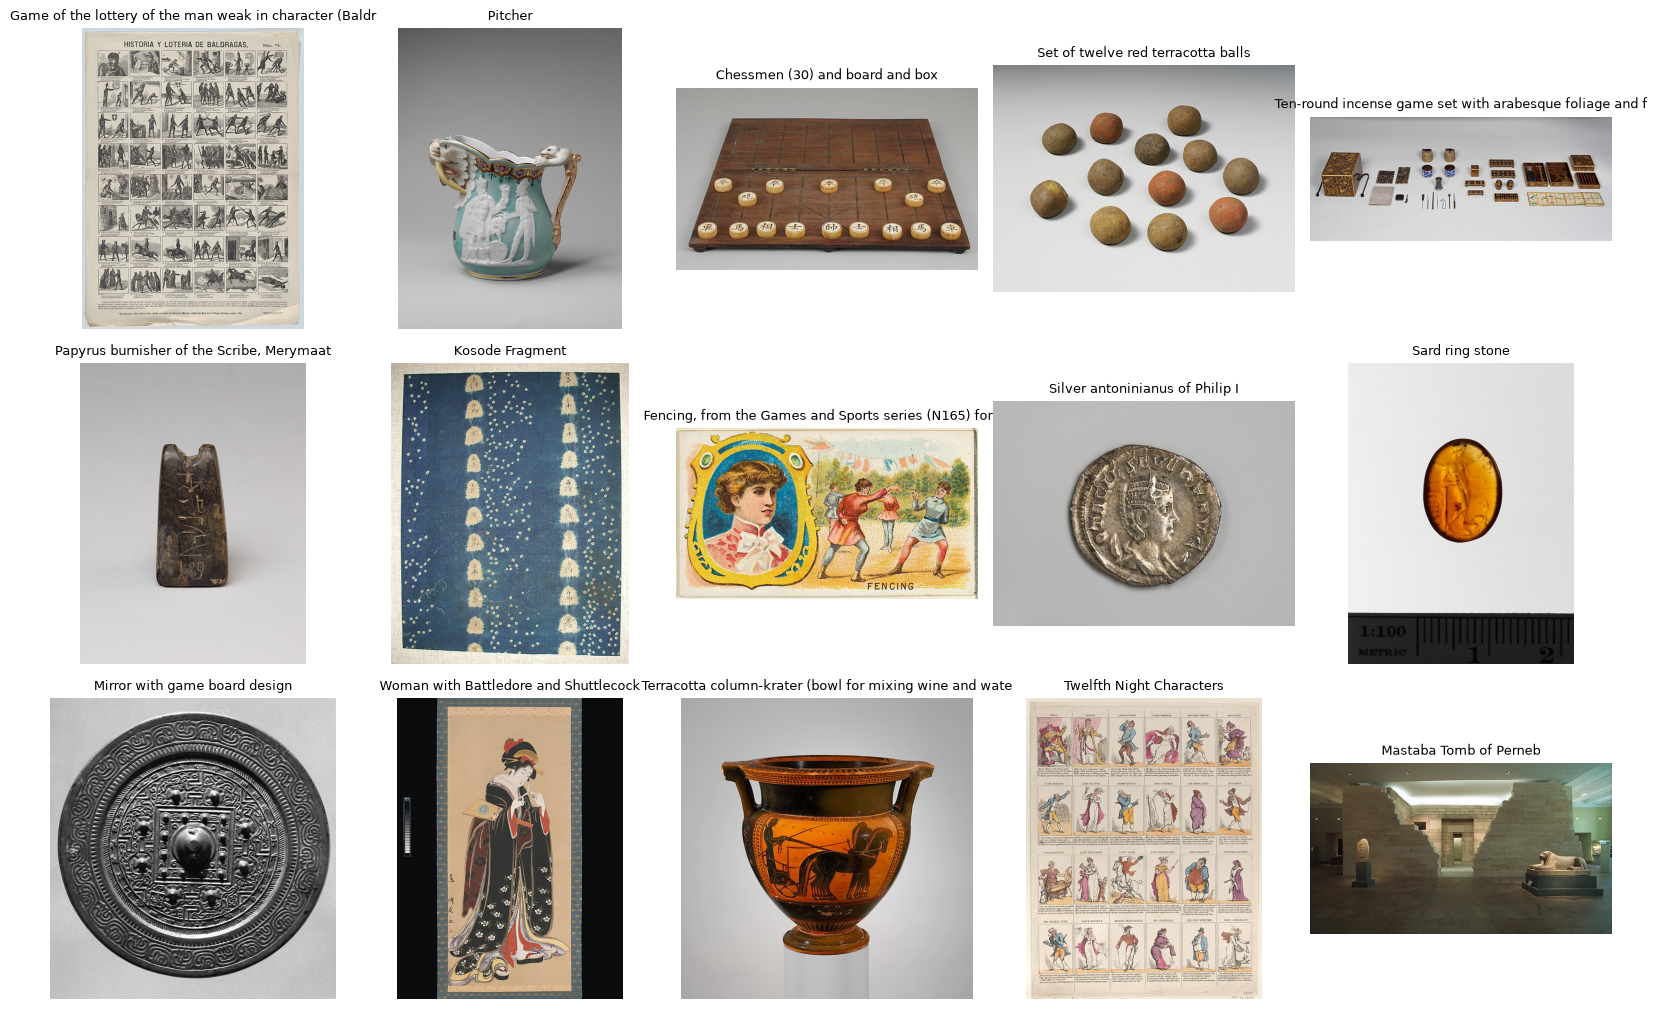

In [50]:
manifest_path = DATA_DIR / "manifest.csv"
manifest.to_csv(manifest_path, index=False, encoding="utf-8")
print("Saved:", manifest_path.resolve())
show_image_grid(manifest, columns=5, max_items=15)

### Optional: use images collected in Workshop 1

Set `USE_LOCAL_IMAGES = True` and put `.jpg`, `.jpeg`, `.png` or `.webp` files in `workshop2_data/my_images/`. This replaces the API manifest for the model sections below. Source and rights information should be completed manually before publication.

In [51]:
# STUDENT CHOICE 3: change False to True only if you added your own images above.
USE_LOCAL_IMAGES = True 
MY_IMAGES_DIR = Path("/Users/gaojiaxi/Desktop/workshop2_data/game_characters_stylised")
MY_IMAGES_DIR.mkdir(exist_ok=True)

if USE_LOCAL_IMAGES:
    valid_extensions = {".jpg", ".jpeg", ".png", ".webp"}
    local_files = sorted(
        p for p in MY_IMAGES_DIR.rglob("*")
        if p.is_file() and p.suffix.lower() in valid_extensions
    )
    manifest = pd.DataFrame([
        {
            "id": f"local_{i:04d}",
            "object_id": "",
            "title": path.stem,
            "creator": "",
            "date": "",
            "medium": "",
            "culture": "",
            "source_url": "",      # complete this
            "image_url": "",
            "license": "unknown", # complete this
            "query": "local dataset",
            "local_path": str(path.resolve()),
        }
        for i, path in enumerate(local_files)
    ])
    manifest.to_csv(manifest_path, index=False, encoding="utf-8")
    print(f"Loaded {len(manifest)} local images.")
    show_image_grid(manifest)
else:
    print("Continuing with the API dataset.")

Loaded 0 local images.
No images to display.


## 2. CLIP — semantic similarity

CLIP maps images and text into the same embedding space. We can therefore ask:

- Which image is most similar to a sentence?
- Which images are visually/semantically close to a selected image?
- How can the dataset be arranged in two dimensions?

### Explicit checkpoint download

The next cell downloads the complete PyTorch CLIP checkpoint and processor configuration from Hugging Face into:

`workshop2_data/checkpoints/clip-vit-base-patch32/`

Re-running the cell uses the local cache and does not download unchanged files again.

In [52]:
from pathlib import Path

BASE_DIR = Path.home() / "Desktop" / "workshop2_data"
CLIP_MODEL_ID = "openai/clip-vit-base-patch32"
CLIP_CHECKPOINT_DIR = BASE_DIR / "checkpoints" / "clip-vit-base-patch32"

CLIP_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

print("CLIP 模型来源：", CLIP_MODEL_ID)
print("模型保存位置：", CLIP_CHECKPOINT_DIR)


CLIP 模型来源： openai/clip-vit-base-patch32
模型保存位置： /Users/gaojiaxi/Desktop/workshop2_data/checkpoints/clip-vit-base-patch32


In [54]:
from transformers import CLIPModel, CLIPProcessor

clip_model = CLIPModel.from_pretrained(CLIP_CHECKPOINT_DIR).to(DEVICE).eval()
clip_processor = CLIPProcessor.from_pretrained(CLIP_CHECKPOINT_DIR)

print("Loaded:", CLIP_MODEL_ID)
print("Device:", DEVICE)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loaded: openai/clip-vit-base-patch32
Device: mps


In [61]:
if manifest.empty:
    raise ValueError("The manifest is empty. Run the API section or add local images first.")

image_paths = manifest["local_path"].tolist()
batch_size = 16 if DEVICE == "cuda" else 8
feature_batches = []

for start in tqdm(range(0, len(image_paths), batch_size), desc="CLIP image embeddings"):
    batch_paths = image_paths[start:start + batch_size]
    batch_images = [Image.open(path).convert("RGB") for path in batch_paths]
    inputs = clip_processor(images=batch_images, return_tensors="pt")
    inputs = {key: value.to(DEVICE) for key, value in inputs.items()}

    with torch.inference_mode():
        feature_output = clip_model.get_image_features(**inputs)
        # Transformers 5 returns a structured output; older versions return a tensor.
        features = (
            feature_output.pooler_output
            if hasattr(feature_output, "pooler_output")
            else feature_output
        )
        features = features / features.norm(dim=-1, keepdim=True)

    feature_batches.append(features.cpu().float().numpy())

image_embeddings = np.vstack(feature_batches)
embeddings_path = OUTPUTS_DIR / "clip_image_embeddings.npy"
np.save(embeddings_path, image_embeddings)

print("Embedding matrix:", image_embeddings.shape)
print("Saved:", embeddings_path.resolve())

CLIP image embeddings:   0%|          | 0/75 [00:00<?, ?it/s]

Embedding matrix: (600, 512)
Saved: /Users/gaojiaxi/Desktop/workshop2_data/outputs/clip_image_embeddings.npy


In [62]:
from pathlib import Path
import os

BASE_DIR = Path.home() / "Desktop" / "workshop2_data"

print("数据文件夹存在：", BASE_DIR.exists())
print("文件夹内容：")

for p in BASE_DIR.iterdir():
    print(p.name, "— 文件" if p.is_file() else "— 文件夹")

数据文件夹存在： True
文件夹内容：
video — 文件夹
azurlane — 文件夹
.DS_Store — 文件
images — 文件夹
game_characters_realistic — 文件夹
game_characters_stylised — 文件夹
checkpoints — 文件夹
arknights — 文件夹
manifest.csv — 文件
outputs — 文件夹


In [63]:
from pathlib import Path
import pandas as pd

BASE_DIR = Path.home() / "Desktop" / "workshop2_data"
manifest_path = BASE_DIR / "manifest.csv"

manifest = pd.read_csv(manifest_path)

print("图片总数：", len(manifest))
print("清单列名：", manifest.columns.tolist())
print(manifest["game"].value_counts())
print(manifest[["game", "local_path"]].head())

图片总数： 600
清单列名： ['id', 'title', 'game', 'local_path', 'source_url', 'license']
game
arknights    300
azurlane     300
Name: count, dtype: int64
        game                                         local_path
0  arknights  /Users/gaojiaxi/Desktop/workshop2_data/arknigh...
1  arknights  /Users/gaojiaxi/Desktop/workshop2_data/arknigh...
2  arknights  /Users/gaojiaxi/Desktop/workshop2_data/arknigh...
3  arknights  /Users/gaojiaxi/Desktop/workshop2_data/arknigh...
4  arknights  /Users/gaojiaxi/Desktop/workshop2_data/arknigh...


In [64]:
from pathlib import Path

p = Path.home() / "Desktop" / "workshop2_data" / "manifest.csv"

print("文件存在：", p.exists())
print("文件大小（字节）：", p.stat().st_size if p.exists() else "不存在")

if p.exists():
    print("文件前 500 个字符：")
    print(p.read_text(encoding="utf-8-sig")[:500])

文件存在： True
文件大小（字节）： 78012
文件前 500 个字符：
id,title,game,local_path,source_url,license
arknights_0000,A42_默认服装_精英零,arknights,/Users/gaojiaxi/Desktop/workshop2_data/arknights/A42_默认服装_精英零.png,,unknown
arknights_0001,A43_默认服装_精英零,arknights,/Users/gaojiaxi/Desktop/workshop2_data/arknights/A43_默认服装_精英零.png,,unknown
arknights_0002,A44_默认服装_精英零,arknights,/Users/gaojiaxi/Desktop/workshop2_data/arknights/A44_默认服装_精英零.png,,unknown
arknights_0003,AA00_默认服装_精英零,arknights,/Users/gaojiaxi/Desktop/workshop2_data/arknights/AA00_默认服装_精英零.png,,unknown
ar


In [65]:

from pathlib import Path
import pandas as pd

BASE_DIR = Path.home() / "Desktop" / "workshop2_data"
manifest_path = BASE_DIR / "manifest.csv"

manifest = pd.read_csv(manifest_path)

print("图片总数：", len(manifest))
print("\n各组数量：")
print(manifest["game"].value_counts())
print("\n前几条图片路径：")
print(manifest[["game", "local_path"]].head())


图片总数： 600

各组数量：
game
arknights    300
azurlane     300
Name: count, dtype: int64

前几条图片路径：
        game                                         local_path
0  arknights  /Users/gaojiaxi/Desktop/workshop2_data/arknigh...
1  arknights  /Users/gaojiaxi/Desktop/workshop2_data/arknigh...
2  arknights  /Users/gaojiaxi/Desktop/workshop2_data/arknigh...
3  arknights  /Users/gaojiaxi/Desktop/workshop2_data/arknigh...
4  arknights  /Users/gaojiaxi/Desktop/workshop2_data/arknigh...


In [66]:
from pathlib import Path
import pandas as pd

BASE_DIR = Path.home() / "Desktop" / "workshop2_data"

rows = []

for game in ["arknights", "azurlane"]:
    folder = BASE_DIR / game
    valid_ext = {".jpg", ".jpeg", ".png", ".webp"}

    files = sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in valid_ext
    )

    print(game, "找到图片：", len(files))

    for i, path in enumerate(files):
        rows.append({
            "id": f"{game}_{i:04d}",
            "title": path.stem,
            "game": game,
            "local_path": str(path.resolve()),
            "source_url": "",
            "license": "unknown"
        })

manifest = pd.DataFrame(rows)

manifest_path = BASE_DIR / "manifest.csv"
manifest.to_csv(manifest_path, index=False, encoding="utf-8")

print("\n清单已重建：", manifest_path)
print("总图片数：", len(manifest))
print(manifest["game"].value_counts())
print("清单列名：", manifest.columns.tolist())
display(manifest.head())

arknights 找到图片： 300
azurlane 找到图片： 300

清单已重建： /Users/gaojiaxi/Desktop/workshop2_data/manifest.csv
总图片数： 600
game
arknights    300
azurlane     300
Name: count, dtype: int64
清单列名： ['id', 'title', 'game', 'local_path', 'source_url', 'license']


,id,title,game,local_path,source_url,license
0,arknights_0000,A42_默认服装_精英零,arknights,/Users/gaojiaxi/Desktop/workshop2_data/arknigh...,,unknown
1,arknights_0001,A43_默认服装_精英零,arknights,/Users/gaojiaxi/Desktop/workshop2_data/arknigh...,,unknown
2,arknights_0002,A44_默认服装_精英零,arknights,/Users/gaojiaxi/Desktop/workshop2_data/arknigh...,,unknown
3,arknights_0003,AA00_默认服装_精英零,arknights,/Users/gaojiaxi/Desktop/workshop2_data/arknigh...,,unknown
4,arknights_0004,AA01_默认服装_精英二,arknights,/Users/gaojiaxi/Desktop/workshop2_data/arknigh...,,unknown


In [67]:
if manifest.empty:
    raise ValueError("The manifest is empty. Run the API section or add local images first.")

image_paths = manifest["local_path"].tolist()
batch_size = 16 if DEVICE == "cuda" else 8
feature_batches = []

for start in tqdm(range(0, len(image_paths), batch_size), desc="CLIP image embeddings"):
    batch_paths = image_paths[start:start + batch_size]
    batch_images = [Image.open(path).convert("RGB") for path in batch_paths]
    inputs = clip_processor(images=batch_images, return_tensors="pt")
    inputs = {key: value.to(DEVICE) for key, value in inputs.items()}

    with torch.inference_mode():
        feature_output = clip_model.get_image_features(**inputs)
        # Transformers 5 returns a structured output; older versions return a tensor.
        features = (
            feature_output.pooler_output
            if hasattr(feature_output, "pooler_output")
            else feature_output
        )
        features = features / features.norm(dim=-1, keepdim=True)

    feature_batches.append(features.cpu().float().numpy())

image_embeddings = np.vstack(feature_batches)
embeddings_path = OUTPUTS_DIR / "clip_image_embeddings.npy"
np.save(embeddings_path, image_embeddings)

print("Embedding matrix:", image_embeddings.shape)
print("Saved:", embeddings_path.resolve())

CLIP image embeddings:   0%|          | 0/75 [00:00<?, ?it/s]

Embedding matrix: (600, 512)
Saved: /Users/gaojiaxi/Desktop/workshop2_data/outputs/clip_image_embeddings.npy


,title,game,clip_similarity
507,Pungent_Plum_Default,azurlane,0.252619
349,Azure_Gold_Summer_Night_Default,azurlane,0.249561
77,CB25_默认服装_精英二,arknights,0.249193
559,Superstar_of_the_Blue_Seas,azurlane,0.247276
487,Occult_Clash_Default,azurlane,0.242966
538,Silent_Night_Songstress,azurlane,0.242491
474,Morning_Sun_Over_Azure_Skies_Default,azurlane,0.241465
456,Lights_of_the_Lantern_Festival,azurlane,0.240629
501,Porcelain_Grace_Default,azurlane,0.239767
253,永恒玩家,arknights,0.238123


/var/folders/9x/589zt6mn6ggg2qfnw46n_wsm0000gn/T/ipykernel_5316/135577360.py:28: UserWarning: Glyph 40664 (\N{CJK UNIFIED IDEOGRAPH-9ED8}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9x/589zt6mn6ggg2qfnw46n_wsm0000gn/T/ipykernel_5316/135577360.py:28: UserWarning: Glyph 35748 (\N{CJK UNIFIED IDEOGRAPH-8BA4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9x/589zt6mn6ggg2qfnw46n_wsm0000gn/T/ipykernel_5316/135577360.py:28: UserWarning: Glyph 26381 (\N{CJK UNIFIED IDEOGRAPH-670D}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9x/589zt6mn6ggg2qfnw46n_wsm0000gn/T/ipykernel_5316/135577360.py:28: UserWarning: Glyph 35013 (\N{CJK UNIFIED IDEOGRAPH-88C5}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9x/589zt6mn6ggg2qfnw46n_wsm0000gn/T/ipykernel_5316/135577360.py:28: UserWarning: Glyph 31934 (\N{CJK UNIFIED IDEOGRAPH-7CBE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9x/589zt6mn6ggg2q

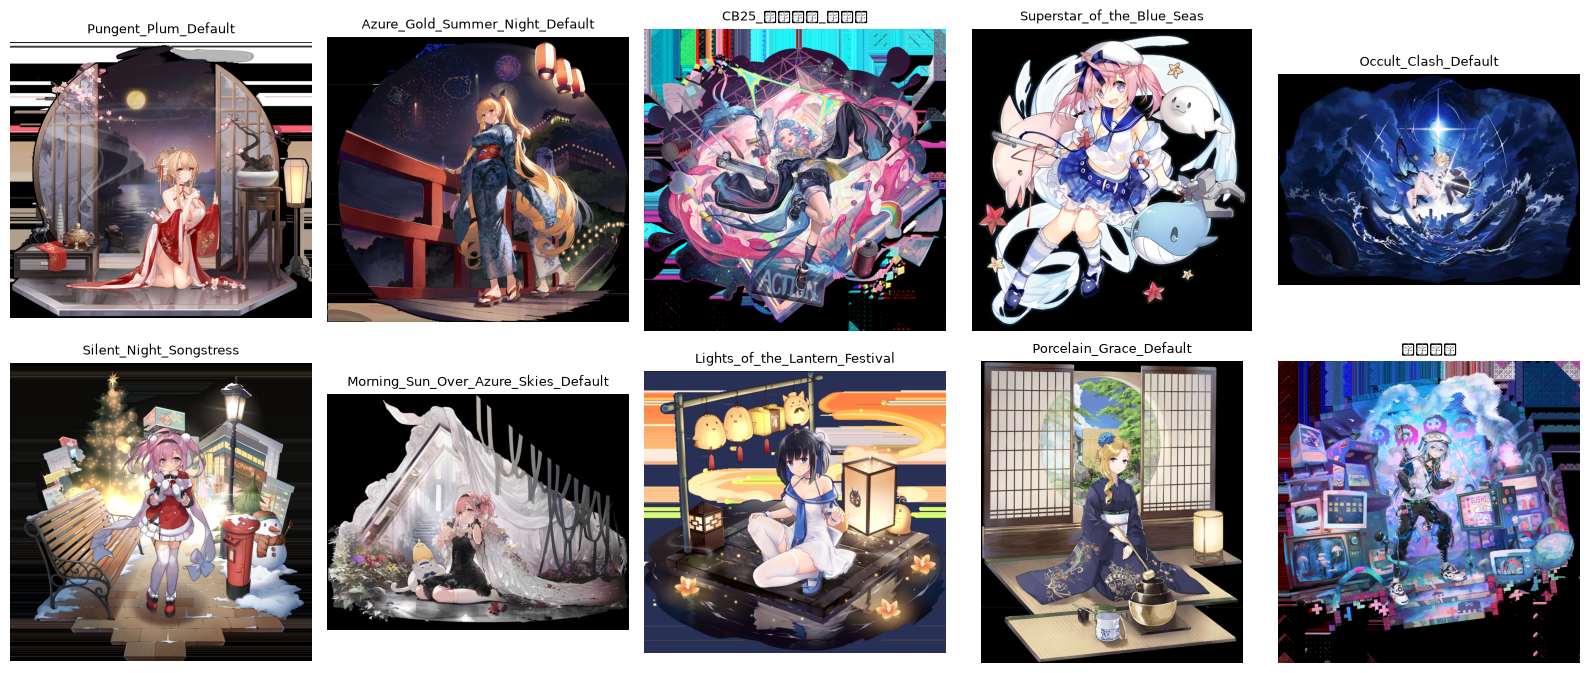

In [68]:
def search_images_with_text(query, top_k=8):
    text_inputs = clip_processor(text=[query], return_tensors="pt", padding=True)
    text_inputs = {key: value.to(DEVICE) for key, value in text_inputs.items()}

    with torch.inference_mode():
        text_feature_output = clip_model.get_text_features(**text_inputs)
        # Use the projected tensor from either the new or older API.
        text_features = (
            text_feature_output.pooler_output
            if hasattr(text_feature_output, "pooler_output")
            else text_feature_output
        )
        text_features = text_features / text_features.norm(dim=-1, keepdim=True)

    similarities = image_embeddings @ text_features.cpu().float().numpy()[0]
    order = np.argsort(similarities)[::-1][:top_k]
    results = manifest.iloc[order].copy()
    results["clip_similarity"] = similarities[order]
    return results


# STUDENT CHOICE 4: describe something you want to find in plain language.
TEXT_QUERY = "a painting with stars"
text_results = search_images_with_text(TEXT_QUERY, top_k=10)
display(
    text_results[
        [
            col for col in ["title", "game", "clip_similarity"]
            if col in text_results.columns
        ]
    ]
)

show_image_grid(text_results, columns=5, max_items=10)

Selected image: AA04_默认服装_精英二


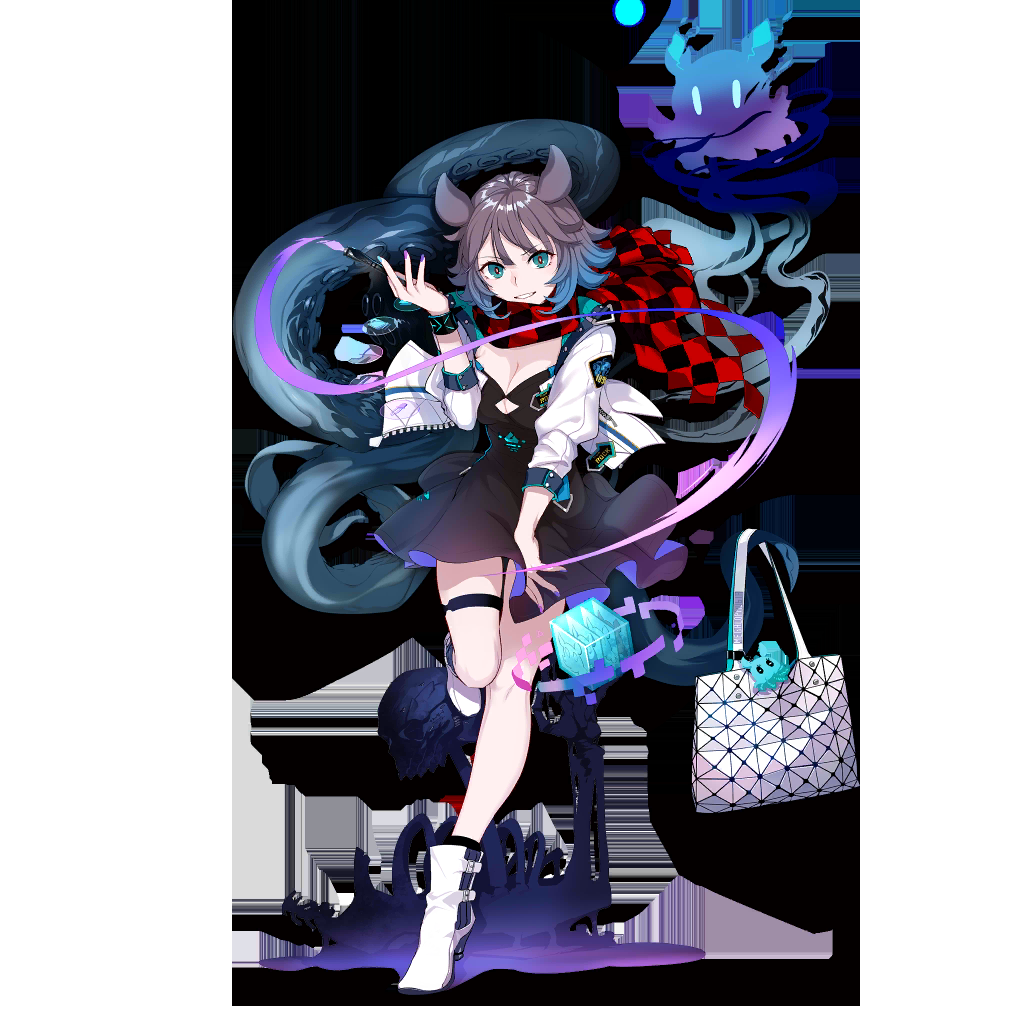

,title,game,clip_similarity
207,君子兰,arknights,0.879602
129,HK03_默认服装_精英二,arknights,0.845269
27,B215_默认服装_精英零,arknights,0.837777
166,JC00_默认服装_精英零,arknights,0.832857
523,Sakura_Elegance,azurlane,0.832351
148,II04_默认服装_精英零,arknights,0.827046
161,IU05_默认服装_精英二,arknights,0.826463
30,BS01_默认服装_精英二,arknights,0.823256
139,HK13_默认服装_精英二,arknights,0.822311
275,翡翠假日,arknights,0.820455


/var/folders/9x/589zt6mn6ggg2qfnw46n_wsm0000gn/T/ipykernel_5316/135577360.py:28: UserWarning: Glyph 21531 (\N{CJK UNIFIED IDEOGRAPH-541B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9x/589zt6mn6ggg2qfnw46n_wsm0000gn/T/ipykernel_5316/135577360.py:28: UserWarning: Glyph 23376 (\N{CJK UNIFIED IDEOGRAPH-5B50}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9x/589zt6mn6ggg2qfnw46n_wsm0000gn/T/ipykernel_5316/135577360.py:28: UserWarning: Glyph 20848 (\N{CJK UNIFIED IDEOGRAPH-5170}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9x/589zt6mn6ggg2qfnw46n_wsm0000gn/T/ipykernel_5316/135577360.py:28: UserWarning: Glyph 40664 (\N{CJK UNIFIED IDEOGRAPH-9ED8}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9x/589zt6mn6ggg2qfnw46n_wsm0000gn/T/ipykernel_5316/135577360.py:28: UserWarning: Glyph 35748 (\N{CJK UNIFIED IDEOGRAPH-8BA4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/9x/589zt6mn6ggg2q

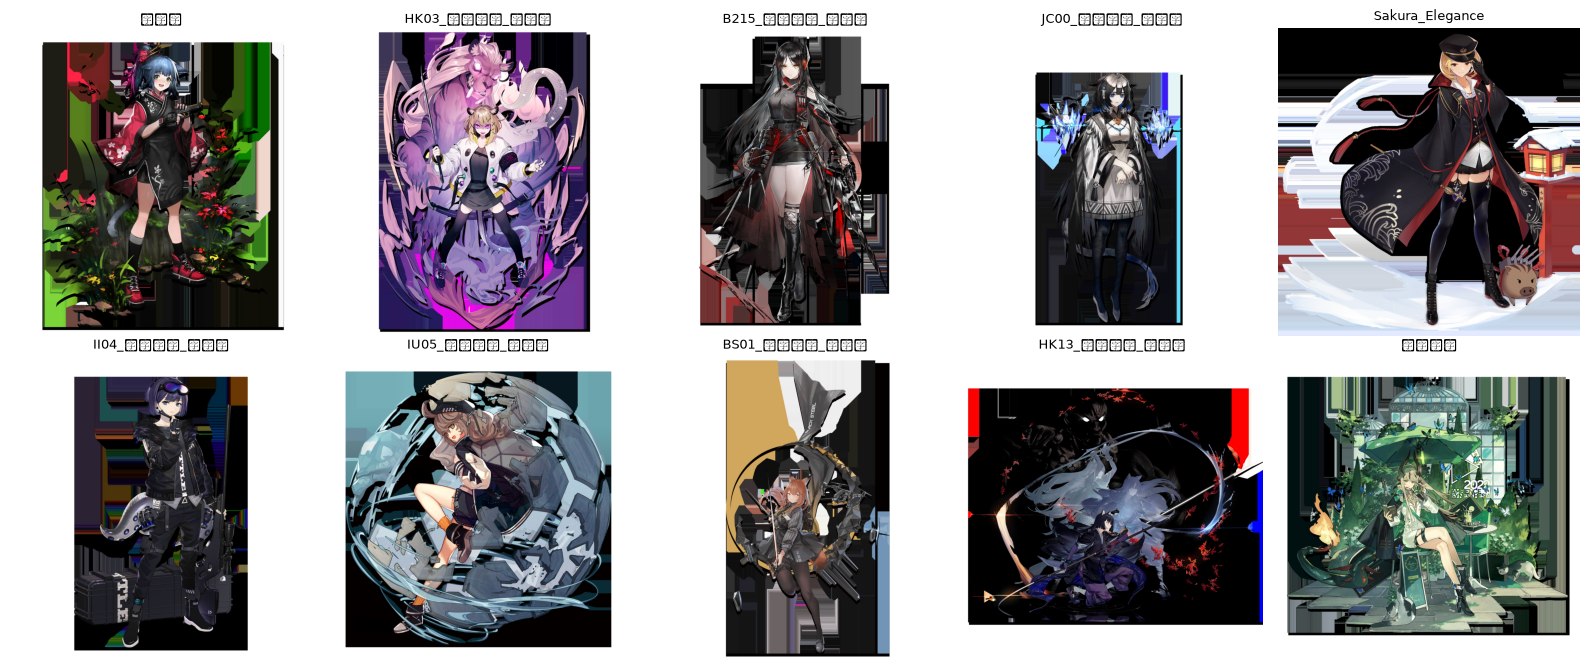

In [69]:
def nearest_images(image_index, top_k=8):
    similarities = image_embeddings @ image_embeddings[image_index]
    order = np.argsort(similarities)[::-1]
    order = order[order != image_index][:top_k]
    results = manifest.iloc[order].copy()
    results["clip_similarity"] = similarities[order]
    return results


# STUDENT CHOICE 5: choose a row number from 0 to len(manifest) - 1.
SELECTED_IMAGE_INDEX = 10 # replace with any row
print("Selected image:", manifest.iloc[SELECTED_IMAGE_INDEX]["title"])
display(Image.open(manifest.iloc[SELECTED_IMAGE_INDEX]["local_path"]).convert("RGB"))

neighbour_results = nearest_images(SELECTED_IMAGE_INDEX, top_k=10)
display(
    neighbour_results[
        [
            col for col in ["title", "game", "clip_similarity"]
            if col in neighbour_results.columns
        ]
    ]
)
show_image_grid(neighbour_results, columns=5, max_items=10)

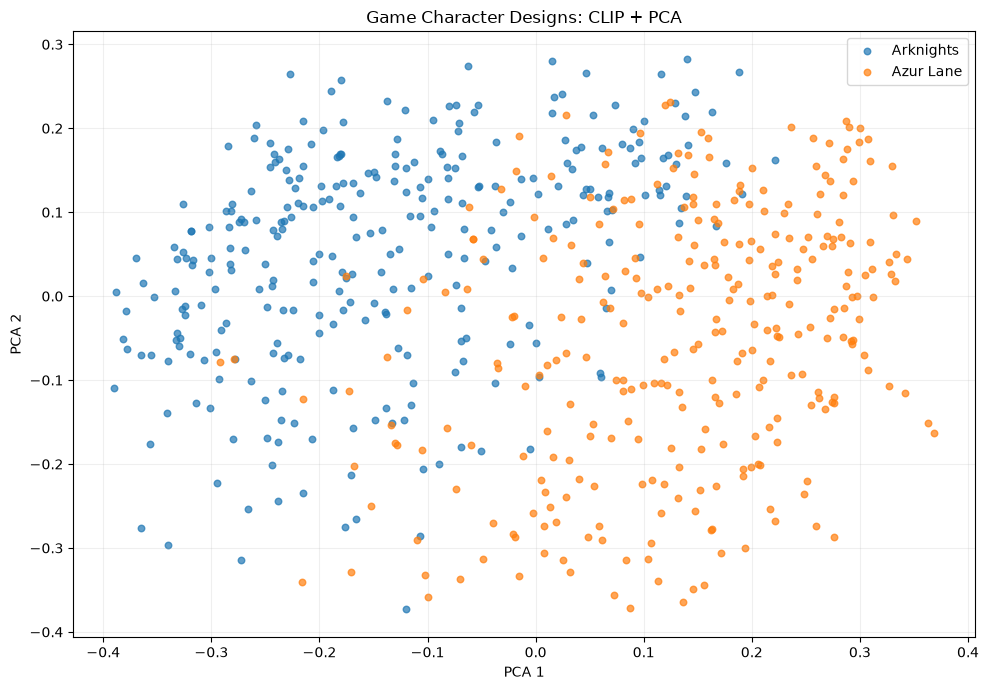

PCA explained variance ratio: [     0.1403    0.084311]
Total variance explained: 0.2246


In [70]:

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# 将 CLIP 特征压缩到二维
pca = PCA(n_components=2)
embedding_2d = pca.fit_transform(image_embeddings)

manifest["clip_x"] = embedding_2d[:, 0]
manifest["clip_y"] = embedding_2d[:, 1]

# 按游戏分别绘制，不给每个点添加文字，避免拥挤
plt.figure(figsize=(10, 7))

for game, label in [
    ("arknights", "Arknights"),
    ("azurlane", "Azur Lane")
]:
    subset = manifest[manifest["game"] == game]
    plt.scatter(
        subset["clip_x"],
        subset["clip_y"],
        alpha=0.7,
        s=22,
        label=label
    )

plt.title("Game Character Designs: CLIP + PCA")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("PCA explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance explained:", round(pca.explained_variance_ratio_.sum(), 4))


## 3. YOLO - audit a closed vocabulary

YOLO26 is trained to recognise a fixed set of everyday COCO categories. It returns bounding boxes, class IDs and confidence scores, which we convert into `detections.csv`.

For architectural ornaments, drawings and artworks, many predictions may be absent or wrong. **That failure is an analytical result:** it tells us what the model's training vocabulary cannot describe. A larger YOLO26 checkpoint may improve accuracy within the same categories, but it does not create a new vocabulary.

### Explicit checkpoint download

Ultralytics downloads official checkpoints the first time a model name is loaded. We load the lightweight `yolo26n.pt` checkpoint for this audit. **SAM will not depend on these YOLO boxes.**

In [71]:
from ultralytics import YOLO, settings

settings.update({
    "weights_dir": str(CHECKPOINTS_DIR.resolve()),
    "runs_dir": str((OUTPUTS_DIR / "runs").resolve()),
})

YOLO_CHECKPOINT = "yolo26n.pt"
yolo_model = YOLO(YOLO_CHECKPOINT)  # downloads the checkpoint if it is absent

print("YOLO checkpoint ready:", YOLO_CHECKPOINT)
print("Ultralytics weights directory:", settings["weights_dir"])
checkpoint_files()

YOLO checkpoint ready: yolo26n.pt
Ultralytics weights directory: /Users/gaojiaxi/Desktop/workshop2_data/checkpoints
checkpoints/clip-vit-base-patch32/pytorch_model.bin  (577.2 MB)
sam2.1_b.pt  (154.4 MB, beside notebook)
yolo26n-pose.pt  (7.5 MB, beside notebook)
yolo26n.pt  (5.3 MB, beside notebook)
yoloe-26s-seg.pt  (29.6 MB, beside notebook)


In [72]:

from pathlib import Path

BASE_DIR = Path.home() / "Desktop" / "workshop2_data"
CHECKPOINTS_DIR = BASE_DIR / "checkpoints"
OUTPUTS_DIR = BASE_DIR / "outputs"

CHECKPOINTS_DIR.mkdir(parents=True, exist_ok=True)
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)

print("检查点目录：", CHECKPOINTS_DIR)
print("输出目录：", OUTPUTS_DIR)

checkpoint_files()

检查点目录： /Users/gaojiaxi/Desktop/workshop2_data/checkpoints
输出目录： /Users/gaojiaxi/Desktop/workshop2_data/outputs
checkpoints/clip-vit-base-patch32/pytorch_model.bin  (577.2 MB)
sam2.1_b.pt  (154.4 MB, beside notebook)
yolo26n-pose.pt  (7.5 MB, beside notebook)
yolo26n.pt  (5.3 MB, beside notebook)
yoloe-26s-seg.pt  (29.6 MB, beside notebook)


In [73]:

from pathlib import Path
import pandas as pd
from tqdm.auto import tqdm

BASE_DIR = Path.home() / "Desktop" / "workshop2_data"
manifest = pd.read_csv(BASE_DIR / "manifest.csv")

detection_rows = []
failed_images = []

for row in tqdm(manifest.itertuples(index=False),
                total=len(manifest),
                desc="YOLO detections"):

    try:
        result = yolo_model.predict(
            source=str(row.local_path),
            device="cpu",
            imgsz=320,
            conf=0.25,
            verbose=False
        )[0]

        if result.boxes is not None:
            for box in result.boxes:
                class_id = int(box.cls.item())
                xywh = box.xywhn[0].tolist()

                detection_rows.append({
                    "id": row.id,
                    "game": row.game,
                    "image_path": row.local_path,
                    "class_id": class_id,
                    "class_name": yolo_model.names[class_id],
                    "confidence": float(box.conf.item()),
                    "x_center": xywh[0],
                    "y_center": xywh[1],
                    "width": xywh[2],
                    "height": xywh[3]
                })

    except Exception as e:
        failed_images.append({
            "id": row.id,
            "path": row.local_path,
            "error": str(e)
        })

detections = pd.DataFrame(
    detection_rows,
    columns=[
        "id", "game", "image_path", "class_id", "class_name",
        "confidence", "x_center", "y_center", "width", "height"
    ]
)

out_dir = BASE_DIR / "outputs"
out_dir.mkdir(parents=True, exist_ok=True)

detections.to_csv(out_dir / "detections.csv", index=False)
pd.DataFrame(failed_images).to_csv(
    out_dir / "yolo_failed_images.csv", index=False
)

print("图片总数：", len(manifest))
print("检测框总数：", len(detections))
print("失败图片数：", len(failed_images))
print("结果保存位置：", out_dir / "detections.csv")


YOLO detections:   0%|          | 0/600 [00:00<?, ?it/s]

图片总数： 600
检测框总数： 647
失败图片数： 0
结果保存位置： /Users/gaojiaxi/Desktop/workshop2_data/outputs/detections.csv


In [74]:

from pathlib import Path
import pandas as pd

BASE_DIR = Path.home() / "Desktop" / "workshop2_data"
manifest_path = BASE_DIR / "manifest.csv"

manifest = pd.read_csv(manifest_path)

print("图片总数：", len(manifest))
print("当前清单列名：", manifest.columns.tolist())
print(manifest["game"].value_counts())
print(manifest[["game", "local_path"]].head())


图片总数： 600
当前清单列名： ['id', 'title', 'game', 'local_path', 'source_url', 'license']
game
arknights    300
azurlane     300
Name: count, dtype: int64
        game                                         local_path
0  arknights  /Users/gaojiaxi/Desktop/workshop2_data/arknigh...
1  arknights  /Users/gaojiaxi/Desktop/workshop2_data/arknigh...
2  arknights  /Users/gaojiaxi/Desktop/workshop2_data/arknigh...
3  arknights  /Users/gaojiaxi/Desktop/workshop2_data/arknigh...
4  arknights  /Users/gaojiaxi/Desktop/workshop2_data/arknigh...


Selected image: AA04_默认服装_精英二


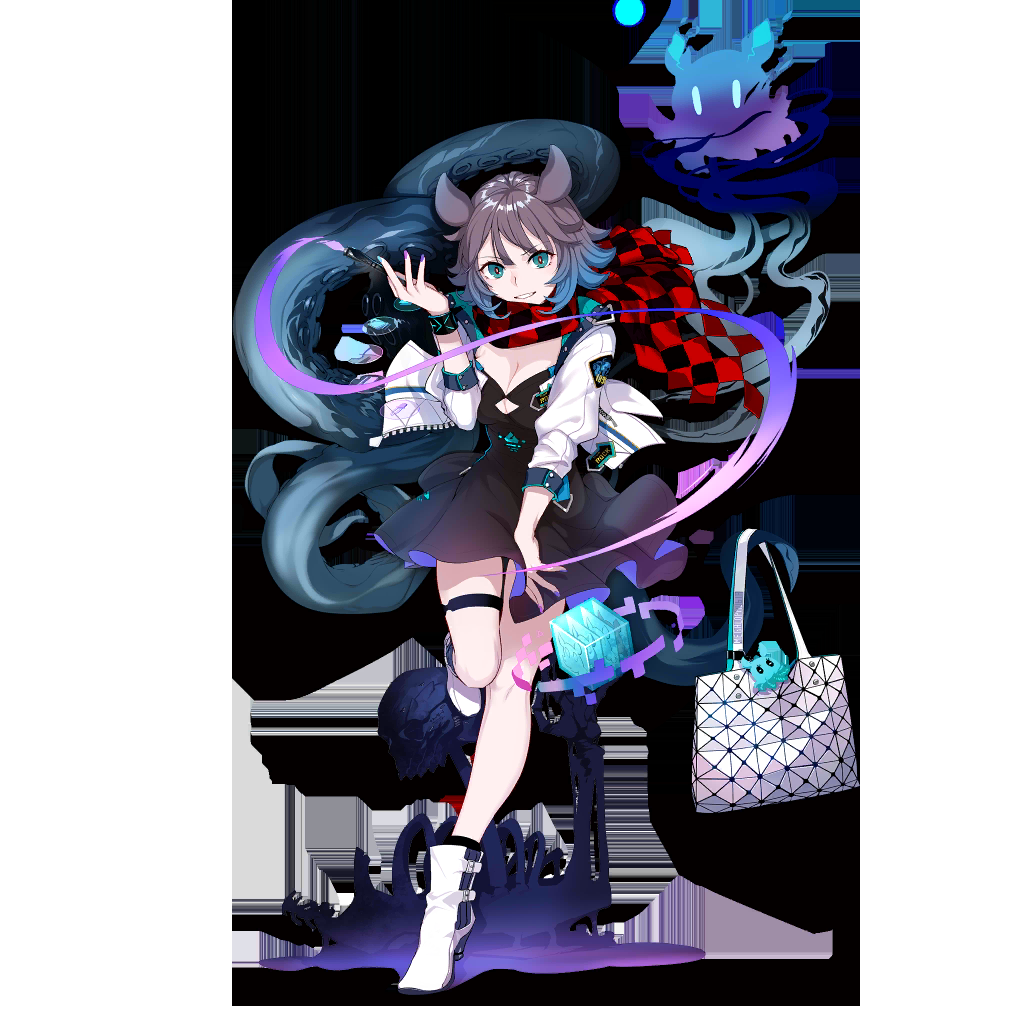

In [75]:
# STUDENT CHOICE 6: choose which image YOLO should demonstrate.
# The default is the same cookbook cover used later for the YOLOE comparison.
DEMO_IMAGE_INDEX = min(10, len(manifest) - 1)
demo_image_path = manifest.iloc[DEMO_IMAGE_INDEX]["local_path"]
print("Selected image:", manifest.iloc[DEMO_IMAGE_INDEX]["title"])
demo_result = yolo_model.predict(
    demo_image_path,
    conf=0.25,
    imgsz=320,
    device="cpu",
    verbose=False,
)[0]

# Ultralytics plotting returns BGR; reverse channels for PIL/RGB display.
annotated_rgb = demo_result.plot()[..., ::-1]
display(Image.fromarray(annotated_rgb))

In [ ]:
if detections.empty:
    detection_counts = pd.DataFrame(index=manifest["id"])
else:
    detection_counts = (
        detections.groupby(["image_id", "class_name"])
        .size()
        .unstack(fill_value=0)
        .add_prefix("detected_")
    )

manifest_enriched = manifest.set_index("id").join(detection_counts).reset_index()
manifest_enriched.to_csv(OUTPUTS_DIR / "manifest_enriched.csv", index=False)

detected_image_count = detections["image_id"].nunique() if not detections.empty else 0
coverage = detected_image_count / len(manifest) if len(manifest) else 0
print(f"YOLO found at least one known COCO object in {detected_image_count}/{len(manifest)} images ({coverage:.1%}).")
print("Inspect the labels visually. A high confidence score does not make an irrelevant label correct.")
display(detection_counts.sum().sort_values(ascending=False).head(15).to_frame("total"))
manifest_enriched.head()

In [ ]:
print("manifest 列名：", manifest.columns.tolist())
print("manifest 行数：", len(manifest))
print("manifest 索引名称：", manifest.index.name)

print("\ndetections 列名：", detections.columns.tolist())
print("detections 行数：", len(detections))
print("detection_counts 索引名称：", detection_counts.index.name)
print("detection_counts 列名：", detection_counts.columns.tolist())

In [83]:
from pathlib import Path
import pandas as pd

BASE_DIR = Path.home() / "Desktop" / "workshop2_data"
p = BASE_DIR / "outputs" / "detections.csv"

print("文件存在：", p.exists())

if p.exists():
    print("文件大小：", p.stat().st_size, "字节")
    detections = pd.read_csv(p)
    print("检测结果行数：", len(detections))
    print("检测结果列名：", detections.columns.tolist())
    display(detections.head())

文件存在： True
文件大小： 132378 字节
检测结果行数： 647
检测结果列名： ['id', 'game', 'image_path', 'class_id', 'class_name', 'confidence', 'x_center', 'y_center', 'width', 'height']


,id,game,image_path,class_id,class_name,confidence,x_center,y_center,width,height
0,arknights_0000,arknights,/Users/gaojiaxi/Desktop/workshop2_data/arknigh...,0,person,0.886060,0.451596,0.503563,0.454766,0.964816
1,arknights_0001,arknights,/Users/gaojiaxi/Desktop/workshop2_data/arknigh...,0,person,0.884176,0.472997,0.501962,0.427403,0.936173
2,arknights_0001,arknights,/Users/gaojiaxi/Desktop/workshop2_data/arknigh...,24,backpack,0.262933,0.610923,0.316751,0.155675,0.264559
3,arknights_0002,arknights,/Users/gaojiaxi/Desktop/workshop2_data/arknigh...,0,person,0.788030,0.454715,0.527368,0.415865,0.884070
4,arknights_0005,arknights,/Users/gaojiaxi/Desktop/workshop2_data/arknigh...,0,person,0.652799,0.508205,0.505006,0.688603,0.947981


In [ ]:
print("manifest 列名：", manifest.columns.tolist())
print("manifest 行数：", len(manifest))
print("manifest 索引名称：", manifest.index.name)

print("\ndetections 列名：", detections.columns.tolist())
print("detections 行数：", len(detections))

print("\ndetection_counts 类型：", type(detection_counts))
print("detection_counts 索引名称：", detection_counts.index.name)
print("detection_counts 列名：", detection_counts.columns.tolist())

In [84]:
from pathlib import Path
import pandas as pd

BASE_DIR = Path.home() / "Desktop" / "workshop2_data"
manifest = pd.read_csv(BASE_DIR / "manifest.csv")
detections = pd.read_csv(BASE_DIR / "outputs" / "detections.csv")

# 兼容当前检测文件的实际列名
detections["image_id"] = detections["id"].astype(str)

# 统计每张图片中每种物体出现的次数
if detections.empty:
    detection_counts = pd.DataFrame(index=manifest["id"])
else:
    detection_counts = (
        detections.groupby(["image_id", "class_name"])
        .size()
        .unstack(fill_value=0)
        .add_prefix("detected_")
    )

# 将检测统计合并到图片清单
manifest = manifest.merge(
    detection_counts,
    left_on="id",
    right_index=True,
    how="left"
)

count_columns = [
    col for col in manifest.columns
    if col.startswith("detected_")
]
manifest[count_columns] = manifest[count_columns].fillna(0).astype(int)

output_path = BASE_DIR / "outputs" / "detection_summary.csv"
manifest.to_csv(output_path, index=False)

print("汇总成功！")
print("图片总数：", len(manifest))
print("检测类别：", count_columns)
print("保存位置：", output_path)
display(manifest[["id", "game"] + count_columns].head())

汇总成功！
图片总数： 600
检测类别： ['detected_backpack', 'detected_banana', 'detected_bench', 'detected_bicycle', 'detected_bird', 'detected_boat', 'detected_book', 'detected_bottle', 'detected_bowl', 'detected_cake', 'detected_car', 'detected_carrot', 'detected_chair', 'detected_clock', 'detected_cup', 'detected_dining table', 'detected_dog', 'detected_donut', 'detected_elephant', 'detected_frisbee', 'detected_handbag', 'detected_horse', 'detected_kite', 'detected_laptop', 'detected_motorcycle', 'detected_mouse', 'detected_orange', 'detected_person', 'detected_potted plant', 'detected_sandwich', 'detected_skateboard', 'detected_skis', 'detected_snowboard', 'detected_sports ball', 'detected_stop sign', 'detected_suitcase', 'detected_surfboard', 'detected_teddy bear', 'detected_tennis racket', 'detected_tie', 'detected_traffic light', 'detected_train', 'detected_truck', 'detected_tv', 'detected_umbrella', 'detected_vase', 'detected_wine glass']
保存位置： /Users/gaojiaxi/Desktop/workshop2_data/outputs/de

,id,game,detected_backpack,detected_banana,detected_bench,detected_bicycle,detected_bird,detected_boat,detected_book,detected_bottle,...,detected_teddy bear,detected_tennis racket,detected_tie,detected_traffic light,detected_train,detected_truck,detected_tv,detected_umbrella,detected_vase,detected_wine glass
0,arknights_0000,arknights,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,arknights_0001,arknights,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,arknights_0002,arknights,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,arknights_0003,arknights,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,arknights_0004,arknights,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## 4. SAM 2.1 - promptable segmentation

SAM answers **which pixels belong to the region I indicate?** It does not need to know the object's name. This makes it much more appropriate for ornament, material, drawings and unfamiliar architectural forms.

Unlike the earlier version of this notebook, SAM is **independent of YOLO**. You will try three modes: a point prompt, a manual box prompt and optional segment-everything mode.

The default `sam2.1_b.pt` checkpoint prioritises segmentation quality. On a slow computer, change it to `sam2.1_t.pt`. A larger checkpoint cannot decide what you mean by itself: the prompt still matters.

### SAM mode A - select a region with one positive point

In [85]:
from ultralytics import SAM

# STUDENT CHOICE 7: use sam2.1_b.pt for quality or sam2.1_t.pt for speed.
SAM_CHECKPOINT = "sam2.1_b.pt"
sam_model = SAM(SAM_CHECKPOINT)  # downloads the checkpoint if it is absent

print("SAM checkpoint ready:", SAM_CHECKPOINT)
checkpoint_files()

SAM checkpoint ready: sam2.1_b.pt
checkpoints/clip-vit-base-patch32/pytorch_model.bin  (577.2 MB)
sam2.1_b.pt  (154.4 MB, beside notebook)
yolo26n-pose.pt  (7.5 MB, beside notebook)
yolo26n.pt  (5.3 MB, beside notebook)
yoloe-26s-seg.pt  (29.6 MB, beside notebook)


Positive point [x, y]: [512, 512]


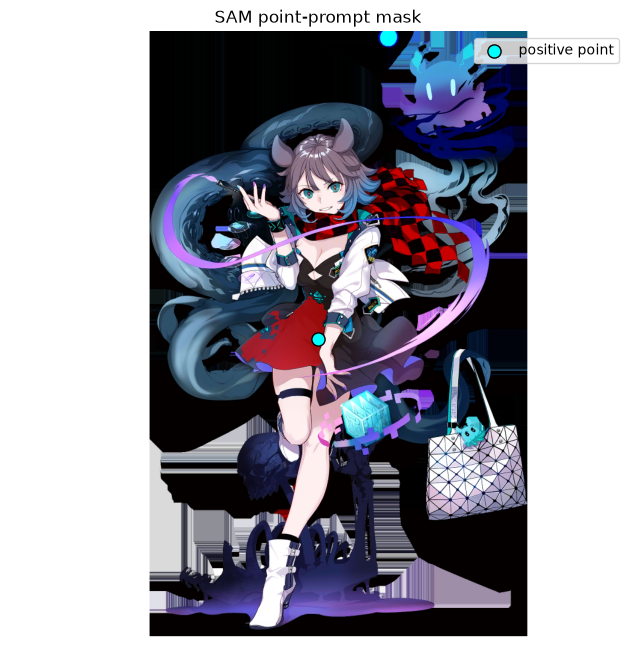

Mask covers 1.0% of the image.
Saved: /Users/gaojiaxi/Desktop/workshop2_data/outputs/sam_masks/arknights_0010_point_mask.png


In [86]:
# A point prompt: tell SAM which visible region you mean.
# STUDENT CHOICE 8: choose the SAM image independently, so this works when YOLO is skipped.
SAM_IMAGE_INDEX = 10
# Fractions are easier than pixel coordinates: 0 is left/top and 1 is right/bottom.
# STUDENT CHOICE 9: move the point by changing these two numbers between 0 and 1.
POINT_X_FRACTION = 0.50
POINT_Y_FRACTION = 0.50

demo_image_path = manifest.iloc[SAM_IMAGE_INDEX]["local_path"]
with Image.open(demo_image_path) as image:
    image_width, image_height = image.size
    demo_image_rgb = image.convert("RGB")

point_prompt = [
    int(image_width * POINT_X_FRACTION),
    int(image_height * POINT_Y_FRACTION),
]
print("Positive point [x, y]:", point_prompt)

sam_point_result = sam_model(
    demo_image_path,
    points=[point_prompt],
    labels=[1],                 # 1 means include this region
    imgsz=1024,
    device=DEVICE,
    verbose=False,
)[0]

if sam_point_result.masks is None:
    print("No mask was returned. Move the point onto a clearer region and rerun this cell.")
else:
    point_mask = sam_point_result.masks.data[0].cpu().numpy() > 0.5
    point_mask_path = MASKS_DIR / f"{manifest.iloc[SAM_IMAGE_INDEX]['id']}_point_mask.png"
    Image.fromarray((point_mask * 255).astype(np.uint8)).save(point_mask_path)

    plt.figure(figsize=(8, 8))
    plt.imshow(demo_image_rgb)
    plt.imshow(np.ma.masked_where(~point_mask, point_mask), cmap="autumn", alpha=0.55)
    plt.scatter(*point_prompt, s=90, c="cyan", edgecolors="black", label="positive point")
    plt.legend()
    plt.title("SAM point-prompt mask")
    plt.axis("off")
    plt.show()

    print(f"Mask covers {point_mask.mean():.1%} of the image.")
    print("Saved:", point_mask_path.resolve())

### SAM mode B - draw an approximate box

A box tells SAM to find the coherent region inside a rectangle. The four fractions below mean **left, top, right, bottom**. They remain valid when image sizes change.

Box [left, top, right, bottom]: [51, 51, 972, 972]


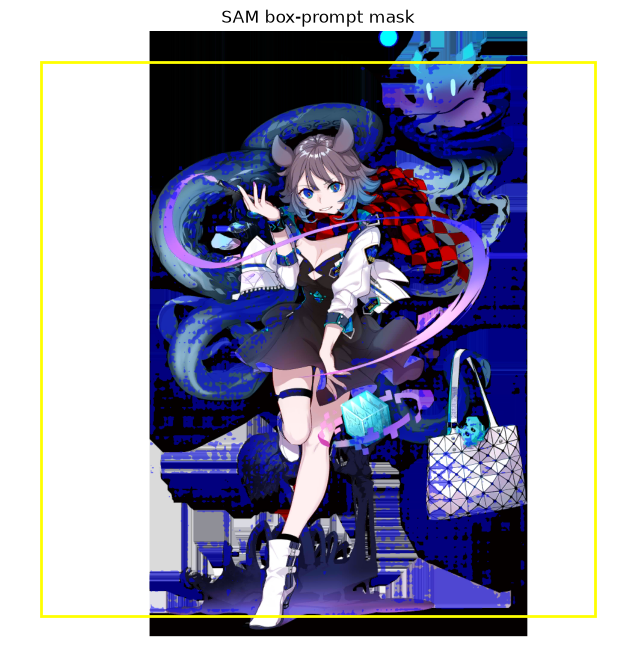

Mask covers 14.9% of the image.
Saved: /Users/gaojiaxi/Desktop/workshop2_data/outputs/sam_masks/arknights_0010_box_mask.png


In [87]:
# STUDENT CHOICE 10: adjust the box edges between 0 and 1.
BOX_LEFT = 0.05
BOX_TOP = 0.05
BOX_RIGHT = 0.95
BOX_BOTTOM = 0.95

box_prompt = [
    int(image_width * BOX_LEFT),
    int(image_height * BOX_TOP),
    int(image_width * BOX_RIGHT),
    int(image_height * BOX_BOTTOM),
]
print("Box [left, top, right, bottom]:", box_prompt)

sam_box_result = sam_model(
    demo_image_path,
    bboxes=box_prompt,
    imgsz=1024,
    device=DEVICE,
    verbose=False,
)[0]

if sam_box_result.masks is None:
    print("No mask was returned. Adjust the box and rerun this cell.")
else:
    box_mask = sam_box_result.masks.data[0].cpu().numpy() > 0.5
    box_mask_path = MASKS_DIR / f"{manifest.iloc[SAM_IMAGE_INDEX]['id']}_box_mask.png"
    Image.fromarray((box_mask * 255).astype(np.uint8)).save(box_mask_path)

    plt.figure(figsize=(8, 8))
    plt.imshow(demo_image_rgb)
    plt.imshow(np.ma.masked_where(~box_mask, box_mask), cmap="winter", alpha=0.5)
    rectangle = plt.Rectangle(
        (box_prompt[0], box_prompt[1]),
        box_prompt[2] - box_prompt[0],
        box_prompt[3] - box_prompt[1],
        fill=False, edgecolor="yellow", linewidth=2,
    )
    plt.gca().add_patch(rectangle)
    plt.title("SAM box-prompt mask")
    plt.axis("off")
    plt.show()

    print(f"Mask covers {box_mask.mean():.1%} of the image.")
    print("Saved:", box_mask_path.resolve())

### SAM mode C - segment everything (optional)

With no prompt, SAM proposes many overlapping regions. This is useful for discovering repeated parts, openings and materials, but it is slower and does not attach names. On a CPU it may take around a minute for one image.

Set `RUN_SEGMENT_EVERYTHING = True` only when you want to run it. The cell filters extremely tiny masks and saves the remaining masks plus a summary table.

In [ ]:
# STUDENT CHOICE 11: change to True to run the slower automatic mode.
RUN_SEGMENT_EVERYTHING = True
MIN_MASK_AREA_FRACTION = 0.001   # ignore masks smaller than 0.1% of the image
MAX_MASKS_TO_KEEP = 40

sam_mask_summary = pd.DataFrame()

if not RUN_SEGMENT_EVERYTHING:
    print("Skipped. Change RUN_SEGMENT_EVERYTHING to True when you want to run this mode.")
else:
    sam_everything_result = sam_model(
        demo_image_path,
        imgsz=1024,
        device=DEVICE,
        verbose=False,
    )[0]

    if sam_everything_result.masks is None:
        print("No automatic masks were returned for this image.")
    else:
        all_masks = sam_everything_result.masks.data.cpu().numpy() > 0.5
        areas = all_masks.sum(axis=(1, 2))
        area_fractions = areas / (all_masks.shape[1] * all_masks.shape[2])
        keep = np.where(area_fractions >= MIN_MASK_AREA_FRACTION)[0]
        keep = keep[np.argsort(areas[keep])[::-1]][:MAX_MASKS_TO_KEEP]

        overlay = np.zeros((*all_masks.shape[1:], 4), dtype=float)
        colours = plt.cm.turbo(np.linspace(0, 1, max(len(keep), 1)))
        summary_rows = []

        for colour, mask_index in zip(colours, keep):
            mask = all_masks[mask_index]
            overlay[mask] = [colour[0], colour[1], colour[2], 0.45]
            mask_path = MASKS_DIR / f"{manifest.iloc[SAM_IMAGE_INDEX]['id']}_auto_{mask_index:03d}.png"
            Image.fromarray((mask * 255).astype(np.uint8)).save(mask_path)
            summary_rows.append({
                "image_id": manifest.iloc[SAM_IMAGE_INDEX]["id"],
                "mask_index": int(mask_index),
                "pixel_area": int(areas[mask_index]),
                "area_fraction": float(area_fractions[mask_index]),
                "mask_path": str(mask_path.resolve()),
            })

        sam_mask_summary = pd.DataFrame(summary_rows)
        sam_summary_path = OUTPUTS_DIR / "sam_mask_summary.csv"
        sam_mask_summary.to_csv(sam_summary_path, index=False)

        plt.figure(figsize=(8, 8))
        plt.imshow(demo_image_rgb)
        plt.imshow(overlay)
        plt.title(f"SAM segment everything: {len(keep)} retained masks")
        plt.axis("off")
        plt.show()

        print(f"SAM proposed {len(all_masks)} masks; retained and saved {len(keep)}.")
        print("Summary:", sam_summary_path.resolve())
        display(sam_mask_summary.head(10))

## 5. YOLOE - open-vocabulary detection and segmentation

Ordinary YOLO asks: *is this one of my fixed COCO categories?* That is why a cookbook cover may be reduced to labels such as `bowl` or `orange`. YOLOE instead accepts categories that **you name** and returns both boxes and masks. This makes it more useful for project-specific visual research.

Run the next cell while connected to the internet. On each student's computer, the first run downloads `yoloe-26s-seg.pt`, installs the text-encoder component and downloads an additional text encoder of about 254 MB; later runs reuse the cached files. The first run can therefore take several minutes. Use short, concrete visual nouns such as `face`, `food`, `flower` or `building`; abstract ideas are harder. Outputs are still propositions, not ground truth.

In [ ]:
# STUDENT CHOICE 12: choose an image row from 0 to len(manifest) - 1.
YOLOE_IMAGE_INDEX = min(20, len(manifest) - 1)

# STUDENT CHOICE 13: replace these with 3-10 concrete things relevant to your project.
# Everyday visual nouns usually work better than abstract concepts.
PROJECT_CLASSES = [
    "table",
    "person",
    "curtain",
    "food",
    "flower",
    "animal",
    "building",
    "landscape",
    "decorative pattern",
    "chair"
]

if manifest.empty:
    raise ValueError("The manifest is empty. Add or download images first.")
if not 0 <= YOLOE_IMAGE_INDEX < len(manifest):
    raise IndexError(f"Choose YOLOE_IMAGE_INDEX between 0 and {len(manifest) - 1}.")

from ultralytics import YOLOE

# The small model is the recommended classroom starting point. On a strong GPU,
# replace the next filename with "yoloe-26m-seg.pt" for more accuracy but slower inference.
YOLOE_CHECKPOINT = "yoloe-26s-seg.pt"
yoloe_image_row = manifest.iloc[YOLOE_IMAGE_INDEX]
yoloe_image_path = yoloe_image_row["local_path"]

print("Selected image:", yoloe_image_row["title"])
print("Prompts:", PROJECT_CLASSES)
display(Image.open(yoloe_image_path).convert("RGB"))

# The first call downloads the YOLOE checkpoint and its text encoder.
yoloe_model = YOLOE(YOLOE_CHECKPOINT)
yoloe_model.set_classes(PROJECT_CLASSES)
yoloe_result = yoloe_model.predict(
    yoloe_image_path,
    conf=0.15,
    imgsz=640,
    device=DEVICE,
    retina_masks=True,  # save masks at the original image resolution
    verbose=False,
)[0]

display(Image.fromarray(yoloe_result.plot()[..., ::-1]))

# Turn the detected boxes into a table that can be used in Workshop 3.
yoloe_rows = []
if yoloe_result.boxes is not None:
    boxes = yoloe_result.boxes.xyxy.cpu().numpy()
    confidences = yoloe_result.boxes.conf.cpu().numpy()
    class_ids = yoloe_result.boxes.cls.cpu().numpy().astype(int)

    for box, confidence, class_id in zip(boxes, confidences, class_ids):
        x1, y1, x2, y2 = box.tolist()
        yoloe_rows.append({
            "image_id": yoloe_image_row["id"],
            "title": yoloe_image_row["title"],
            "class_name": yoloe_result.names[class_id],
            "confidence": float(confidence),
            "x1": float(x1),
            "y1": float(y1),
            "x2": float(x2),
            "y2": float(y2),
        })

yoloe_columns = [
    "image_id", "title", "class_name", "confidence",
    "x1", "y1", "x2", "y2",
]
yoloe_detections = pd.DataFrame(yoloe_rows, columns=yoloe_columns)
yoloe_table_path = OUTPUTS_DIR / "yoloe_detections.csv"
yoloe_detections.to_csv(yoloe_table_path, index=False)
display(yoloe_detections)
print("Saved detection table:", yoloe_table_path.resolve())

if yoloe_result.masks is None:
    print("No masks were found. Try simpler nouns, a different image, or conf=0.10.")
else:
    yoloe_masks = yoloe_result.masks.data.cpu().numpy() > 0.5
    yoloe_dir = OUTPUTS_DIR / "yoloe_masks"
    yoloe_dir.mkdir(exist_ok=True)
    for mask_index, mask in enumerate(yoloe_masks):
        mask_path = yoloe_dir / f"{yoloe_image_row['id']}_{mask_index:03d}.png"
        Image.fromarray((mask * 255).astype(np.uint8)).save(mask_path)
    print(f"Saved {len(yoloe_masks)} YOLOE masks to {yoloe_dir.resolve()}")

## 6. Optional - body movement from video

This section is useful for dance, gesture, performance and occupation studies. It downloads the YOLO26 nano pose checkpoint and converts detected joints into a table.

A standard 720p demonstration video is stored in `workshop2_data/video/body_movement_demo_playable_2SMmL6kIx-w.mp4`. The next cells download the pose checkpoint on each student's computer, process every frame, draw the body skeleton continuously, save all keypoints as a table, and create a playable H.264 overlay video beside the source.

Students can test another video by changing only `VIDEO_PATH`. Full-video CPU processing can take several minutes; set `MAX_POSE_SECONDS = 15` for a quick test before changing it back to `None`. This follows the frame-by-frame YOLO Pose and OpenCV visualization pattern described in the linked reference.

In [ ]:
from ultralytics import YOLO, settings

VIDEO_DIR = DATA_DIR / "video"
VIDEO_DIR.mkdir(exist_ok=True)

# STUDENT CHOICE 14: True runs pose estimation; False skips this extension.
RUN_POSE = True

# STUDENT CHOICE 15: add an MP4 to VIDEO_DIR and replace only this filename.
VIDEO_PATH = VIDEO_DIR / "body_movement_demo_playable_2SMmL6kIx-w.mp4"
VIDEO_SOURCE_URL = "https://www.youtube.com/watch?v=2SMmL6kIx-w"

# None processes the complete video. Use 15 for a faster 15-second test.
MAX_POSE_SECONDS = None

POSE_CHECKPOINT = "yolo26n-pose.pt"
POSE_OVERLAY_PATH = VIDEO_DIR / f"{VIDEO_PATH.stem}_pose_overlay.mp4"

settings.update({"weights_dir": str(CHECKPOINTS_DIR.resolve())})

if RUN_POSE:
    # The checkpoint downloads automatically the first time each student runs this cell.
    pose_model = YOLO(POSE_CHECKPOINT)
    print("Pose checkpoint ready:", POSE_CHECKPOINT)
else:
    print("Pose skipped. Change RUN_POSE to True when you are ready.")

print("Input video: ", VIDEO_PATH.resolve())
print("Overlay video:", POSE_OVERLAY_PATH.resolve())
print("Source:      ", VIDEO_SOURCE_URL)
checkpoint_files()

In [ ]:
import subprocess

import cv2
import imageio_ffmpeg
from IPython.display import Video

COCO_KEYPOINT_NAMES = [
    "nose", "left_eye", "right_eye", "left_ear", "right_ear",
    "left_shoulder", "right_shoulder", "left_elbow", "right_elbow",
    "left_wrist", "right_wrist", "left_hip", "right_hip",
    "left_knee", "right_knee", "left_ankle", "right_ankle",
]

pose_columns = [
    "frame", "time_seconds", "person", "keypoint_id",
    "keypoint", "x", "y", "confidence",
]
pose_rows = []

if not RUN_POSE:
    print("Pose inference skipped.")
elif not VIDEO_PATH.exists():
    raise FileNotFoundError(f"Video not found: {VIDEO_PATH.resolve()}")
else:
    # Read the source video's dimensions and timing.
    video_capture = cv2.VideoCapture(str(VIDEO_PATH))
    if not video_capture.isOpened():
        raise RuntimeError("OpenCV could not open the video. Try another standard MP4 file.")

    video_fps = video_capture.get(cv2.CAP_PROP_FPS) or 25.0
    source_frame_count = int(video_capture.get(cv2.CAP_PROP_FRAME_COUNT))
    video_width = int(video_capture.get(cv2.CAP_PROP_FRAME_WIDTH))
    video_height = int(video_capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
    video_capture.release()

    if MAX_POSE_SECONDS is None:
        frames_to_process = source_frame_count
    else:
        frames_to_process = min(
            source_frame_count,
            max(1, int(MAX_POSE_SECONDS * video_fps)),
        )

    print(
        f"Video: {video_width}x{video_height}, {video_fps:.2f} fps, "
        f"processing {frames_to_process}/{source_frame_count} frames."
    )

    # OpenCV first writes every annotated frame to a temporary video.
    temporary_overlay_path = VIDEO_DIR / f"{VIDEO_PATH.stem}_pose_overlay_working.mp4"
    video_writer = cv2.VideoWriter(
        str(temporary_overlay_path),
        cv2.VideoWriter_fourcc(*"mp4v"),
        video_fps,
        (video_width, video_height),
    )
    if not video_writer.isOpened():
        raise RuntimeError("OpenCV could not create the overlay video.")

    # stream=True avoids loading every result into memory at once.
    pose_stream = pose_model.predict(
        source=str(VIDEO_PATH),
        stream=True,
        imgsz=640,
        conf=0.25,
        device=DEVICE,
        vid_stride=1,       # analyse every frame for a continuous overlay
        verbose=False,
    )

    try:
        for frame_index, result in enumerate(
            tqdm(pose_stream, total=frames_to_process, desc="Drawing pose overlay")
        ):
            if frame_index >= frames_to_process:
                break

            # result.plot() draws the boxes, joints and connecting skeleton.
            annotated_frame = result.plot()
            time_seconds = frame_index / video_fps
            cv2.putText(
                annotated_frame,
                f"Pose estimation | {time_seconds:6.1f} s",
                (20, 40),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.9,
                (0, 255, 255),
                2,
                cv2.LINE_AA,
            )
            video_writer.write(annotated_frame)

            if result.keypoints is None or len(result.keypoints) == 0:
                continue

            xy = result.keypoints.xy.cpu().numpy()
            confidence = (
                result.keypoints.conf.cpu().numpy()
                if result.keypoints.conf is not None
                else np.ones(xy.shape[:2])
            )

            for person_index in range(xy.shape[0]):
                for keypoint_index, keypoint_name in enumerate(COCO_KEYPOINT_NAMES):
                    pose_rows.append({
                        "frame": frame_index,
                        "time_seconds": float(time_seconds),
                        "person": person_index,
                        "keypoint_id": keypoint_index,
                        "keypoint": keypoint_name,
                        "x": float(xy[person_index, keypoint_index, 0]),
                        "y": float(xy[person_index, keypoint_index, 1]),
                        "confidence": float(confidence[person_index, keypoint_index]),
                    })
    finally:
        video_writer.release()

    pose_data = pd.DataFrame(pose_rows, columns=pose_columns)
    pose_path = OUTPUTS_DIR / "pose_keypoints.csv"
    pose_data.to_csv(pose_path, index=False)

    # Convert to H.264/yuv420p for Windows and browser compatibility.
    # The optional audio map copies audio from the source when it exists.
    ffmpeg_exe = imageio_ffmpeg.get_ffmpeg_exe()
    ffmpeg_command = [
        ffmpeg_exe, "-y",
        "-i", str(temporary_overlay_path),
        "-i", str(VIDEO_PATH),
        "-map", "0:v:0",
        "-map", "1:a?",
        "-c:v", "libx264",
        "-preset", "medium",
        "-crf", "20",
        "-pix_fmt", "yuv420p",
        "-c:a", "aac",
        "-b:a", "128k",
        "-movflags", "+faststart",
        "-shortest",
        str(POSE_OVERLAY_PATH),
    ]
    subprocess.run(ffmpeg_command, check=True, capture_output=True, text=True)
    temporary_overlay_path.unlink(missing_ok=True)

    print("Saved keypoints:", pose_path.resolve())
    print("Saved pose video:", POSE_OVERLAY_PATH.resolve())
    display(Video(str(POSE_OVERLAY_PATH), embed=False, width=800))

    if not pose_data.empty:
        wrist = pose_data[
            (pose_data["person"] == 0) &
            (pose_data["keypoint"] == "right_wrist") &
            (pose_data["confidence"] >= 0.25)
        ]
        plt.figure(figsize=(7, 7))
        plt.plot(wrist["x"], wrist["y"], marker=".", linewidth=1)
        plt.gca().invert_yaxis()
        plt.axis("equal")
        plt.title("Right-wrist trajectory — person 0")
        plt.xlabel("x")
        plt.ylabel("y")
        plt.show()

In [6]:
interface_df = manifest_enriched.copy()

# Precompute five neighbours for each item so a simple interface can show "related items".
similarity_matrix = image_embeddings @ image_embeddings.T
neighbour_ids = []
all_ids = manifest["id"].tolist()
for index in range(len(manifest)):
    order = np.argsort(similarity_matrix[index])[::-1]
    order = order[order != index][:5]
    neighbour_ids.append([all_ids[i] for i in order])

interface_df["nearest_ids"] = neighbour_ids

detection_summary = (
    detections.groupby("image_id")["class_name"].apply(list).to_dict()
    if not detections.empty else {}
)
interface_df["detected_objects"] = interface_df["id"].map(
    lambda item_id: detection_summary.get(item_id, [])
)

# Add the project-specific YOLOE labels for the image analysed in Section 5.
yoloe_summary = (
    yoloe_detections.groupby("image_id")["class_name"].apply(list).to_dict()
    if not yoloe_detections.empty else {}
)
interface_df["yoloe_objects"] = interface_df["id"].map(
    lambda item_id: yoloe_summary.get(item_id, [])
)

# Relative paths are easier to move with a future interface project.
interface_df["relative_path"] = interface_df["local_path"].map(
    lambda path: os.path.relpath(path, DATA_DIR)
)

items_path = OUTPUTS_DIR / "items.json"
# Pandas converts NumPy values into standard JSON-compatible Python values.
items = json.loads(interface_df.to_json(orient="records"))
with open(items_path, "w", encoding="utf-8") as file:
    json.dump(items, file, ensure_ascii=False, indent=2)

model_manifest = {
    "clip": CLIP_MODEL_ID,
    "yolo": YOLO_CHECKPOINT,
    "sam": SAM_CHECKPOINT,
    "yoloe": YOLOE_CHECKPOINT,
    "pose_optional": "yolo26n-pose.pt",
    "embedding_shape": list(image_embeddings.shape),
    "notes": "Model outputs require visual inspection and project-specific validation.",
}
model_manifest_path = OUTPUTS_DIR / "model_manifest.json"
with open(model_manifest_path, "w", encoding="utf-8") as file:
    json.dump(model_manifest, file, ensure_ascii=False, indent=2)

manifest_enriched.to_csv(OUTPUTS_DIR / "manifest_enriched.csv", index=False)

print("Interface bundle:")
for path in sorted(OUTPUTS_DIR.iterdir()):
    print(" -", path.name)
print("\nMain interface file:", items_path.resolve())

NameError: name 'manifest_enriched' is not defined



## References

- [Metropolitan Museum of Art Collection API](https://metmuseum.github.io/)
- [OpenAI CLIP repository](https://github.com/openai/CLIP)
- [CLIP ViT-B/32 checkpoint](https://huggingface.co/openai/clip-vit-base-patch32)
- [Ultralytics YOLO26 documentation](https://docs.ultralytics.com/models/yolo26/)
- [Ultralytics SAM 2 documentation](https://docs.ultralytics.com/models/sam-2/)
- [Ultralytics YOLOE documentation](https://docs.ultralytics.com/models/yoloe/)
- [Pose Estimation and Movement Analysis with YOLOv8 and OpenCV](https://medium.com/@aslicandanyildirim/pose-estimation-and-movement-analysis-with-yolov8-and-opencv-60403ecd1800)